# Large Scale: Rate, Preservation und Kompression

**106 Fixed-β-Modelle, 750 Epochen**, Lernrate 0,0005, Split 2. TCGA d=8 (60 Modelle + zwei Weight-Decay-Kontrollen), Circle d=2 (22), Swiss Roll d=2 (22). Keine alten 90-Epochen-Läufe.

Erster Baustein: Was verändert sich mit der Rate? Pearson und Spearman werden **je Datensatz und Trainingsseed über β** berechnet. Danach Median und Streuung über die Seeds; kein unkontrolliertes Pooling verschiedener Datensätze. Diese Korrelationen beschreiben Kompressionsverläufe, noch keinen Zusatznutzen über β und keine Downstream-Güte.

AUC, Mehrskalen-Preservation, Graph und TDA ergänzen wir anschließend. Alle Berechnungen verwenden gespeicherte Daten und starten kein Training.


In [2]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'beta_vae_experiments':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from beta_vae_experiments.large_scale_analysis import collect_large_scale_metrics, rate_correlations, PRESERVATION

EXPERIMENTS = ROOT / 'beta_vae_experiments'
SERIES = EXPERIMENTS / 'large_scale_results/fixed_beta_106_epochs750_2026_10_27'
OUTPUT = EXPERIMENTS / 'analysis_results/large_scale_fixed_beta'
OUTPUT.mkdir(parents=True, exist_ok=True)
RECOMPUTE_METRICS = False
WORKERS = 4
PRIMARY_K = 20
MAX_STRUCTURAL_SAMPLES = 1000
SUBSET_SEED = 31
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True})


## 1. Daten laden und prüfen

Die CPU-Nachberechnung verwendet unseren bestehenden ZADU-Adapter mit unveränderten Bibliotheksformeln. Der Cache speichert je Modell Eingabe-/Posterior-Hashes, Adapter-Hash und Subset-Indizes. Mit `RECOMPUTE_METRICS=True` werden Caches überprüft und fehlende/veraltete Werte neu berechnet.

Preservation: X gegen μ auf derselben festen Teilstichprobe (höchstens 1000, k=20). Rate und Collapse: vollständiger Testsatz. Zusammenfallende Punkte werden bei den unterstützten Rangmaßen mit dokumentierter self-first-/Index-Konvention behandelt; SNC und geometrisch undefinierte Ausgaben bleiben fehlend. Es gibt weder Jitter noch Null-Imputation. SNC verwendet intern seine eigene Nachbarschaftsgröße.


In [3]:
if RECOMPUTE_METRICS:
    runs = collect_large_scale_metrics(ROOT, workers=WORKERS, max_samples=MAX_STRUCTURAL_SAMPLES,
                                      k=PRIMARY_K, seed=SUBSET_SEED)
else:
    path = OUTPUT / 'run_metrics.csv'
    if not path.exists():
        raise FileNotFoundError('Metriken fehlen noch. CPU-Nachberechnung abwarten oder RECOMPUTE_METRICS=True setzen.')
    runs = pd.read_csv(path)
    runs = runs.rename(columns={name: name.replace('_mse_native', '_loss_native') for name in runs.columns})
assert len(runs) == 106 and runs.job_name.is_unique
assert runs.k.eq(PRIMARY_K).all(), 'Loaded cache uses another neighborhood size'
assert runs.epochs.eq(750).all() and runs.anneal_function.eq('no-annealing').all()
assert np.isfinite(runs.rate).all() and runs.rate.ge(0).all()
main = runs[runs.weight_decay.eq(.01)].copy()
controls = runs[runs.weight_decay.eq(0)].copy()
display(runs.groupby(['dataset', 'latent_dim', 'weight_decay']).agg(
    models=('job_name','size'), seeds=('seed','nunique'), beta_levels=('beta_over_d','nunique'),
    n_test=('n_test','first'), fully_collapsed=('full_collapse','sum')))
display(main.groupby('dataset')[list(PRESERVATION)].count().rename_axis('valid metric values per dataset'))

if 'rank_backend' in runs:
    display(runs.groupby(['dataset', 'rank_backend']).agg(
        models=('job_name', 'size'), trustworthiness_available=('trustworthiness', 'count'),
        median_mu_unique_fraction=('mu_float32_unique_fraction', 'median')))


models  seeds  beta_levels  n_test  \
dataset    latent_dim weight_decay                                       
circle     2          0.01              22      2           11    1000   
swiss_roll 2          0.01              22      2           11    1000   
tcga       8          0.00               2      2            1    2003   
                      0.01              60      4           15    2003   

                                    fully_collapsed  
dataset    latent_dim weight_decay                   
circle     2          0.01                        7  
swiss_roll 2          0.01                       10  
tcga       8          0.00                        0  
                      0.01                       11

,trustworthiness,continuity,lcmc,mrre_false,mrre_missing,steadiness,cohesiveness,scale_normalized_stress,spearman_rho
valid metric values per dataset,,,,,,,,,
circle,15,15,15,15,15,0,0,15,15
swiss_roll,12,12,12,12,12,0,0,12,12
tcga,49,49,49,49,49,26,26,49,49


models  trustworthiness_available  \
dataset    rank_backend                                             
circle     native_zadu               7                          0   
           precomputed_float64      15                         15   
swiss_roll native_zadu              10                          0   
           precomputed_float64      12                         12   
tcga       native_zadu              39                         28   
           precomputed_float64      23                         23   

                                median_mu_unique_fraction  
dataset    rank_backend                                    
circle     native_zadu                             0.0010  
           precomputed_float64                     0.4370  
swiss_roll native_zadu                             0.0010  
           precomputed_float64                     0.4275  
tcga       native_zadu                             1.0000  
           precomputed_float64                     0.9480

### Duplikate: korrigierter Rang-Adapter

Der alte Guard unterdrückte sämtliche Nachbarschaftsmaße bei Duplikaten. Jetzt erhalten T/C, MRRE, LCMC, Neighbor Dissimilarity, Procrustes und Topographic Product über die offiziellen ZADU-Argumente vorberechnete Nachbarn: **self auf Rang 0, übrige Gleichstände stabil nach Zeilenindex**, Distanzen in Float64. Ohne Duplikate läuft der bisherige Backend-Pfad unverändert.

Das erzeugt keine neue geometrische Information. Bei vielen Gleichständen hängen Scores von der dokumentierten Reihenfolgekonvention ab. sklearn kann Gleichstände anders auflösen. SNC bleibt ohne geeignete Schnittstelle bei Duplikaten zurückgestellt; distanzbasierte Maße können wegen echter Nullabstände weiterhin undefiniert sein. Vollständig konstante Räume bleiben als undefiniert markiert. Die aktuelle Verfügbarkeit steht in der Tabelle darüber.

Quelle: Lee & Verleysen (2009), Abschnitt 2, S.1432, Text vor Gl.(2): https://perso.uclouvain.be/michel.verleysen/papers/neurocomputing09jl.pdf


## 2. Kompressionsverläufe

Linien zeigen den Median über Seeds, Punkte die Einzelmodelle. β=0 bleibt sichtbar. Rate = mittlere totale KL pro Patient; Active Units verwenden Var(μ)>0,01. Collapse: mindestens 99 % der Patienten mit KL_j<0,01.

Rekonstruktion ist der **native Validation-Rekonstruktionsloss der letzten Epoche**, keine gewöhnliche MSE pro Patient und keine Test-MSE. Der native Trainer summiert Batch-Mittelwerte und teilt durch n; wir korrigieren diese Werte nicht stillschweigend. MSE und Rate dürfen nicht unkritisch zwischen TCGA und Geometrie verglichen werden.


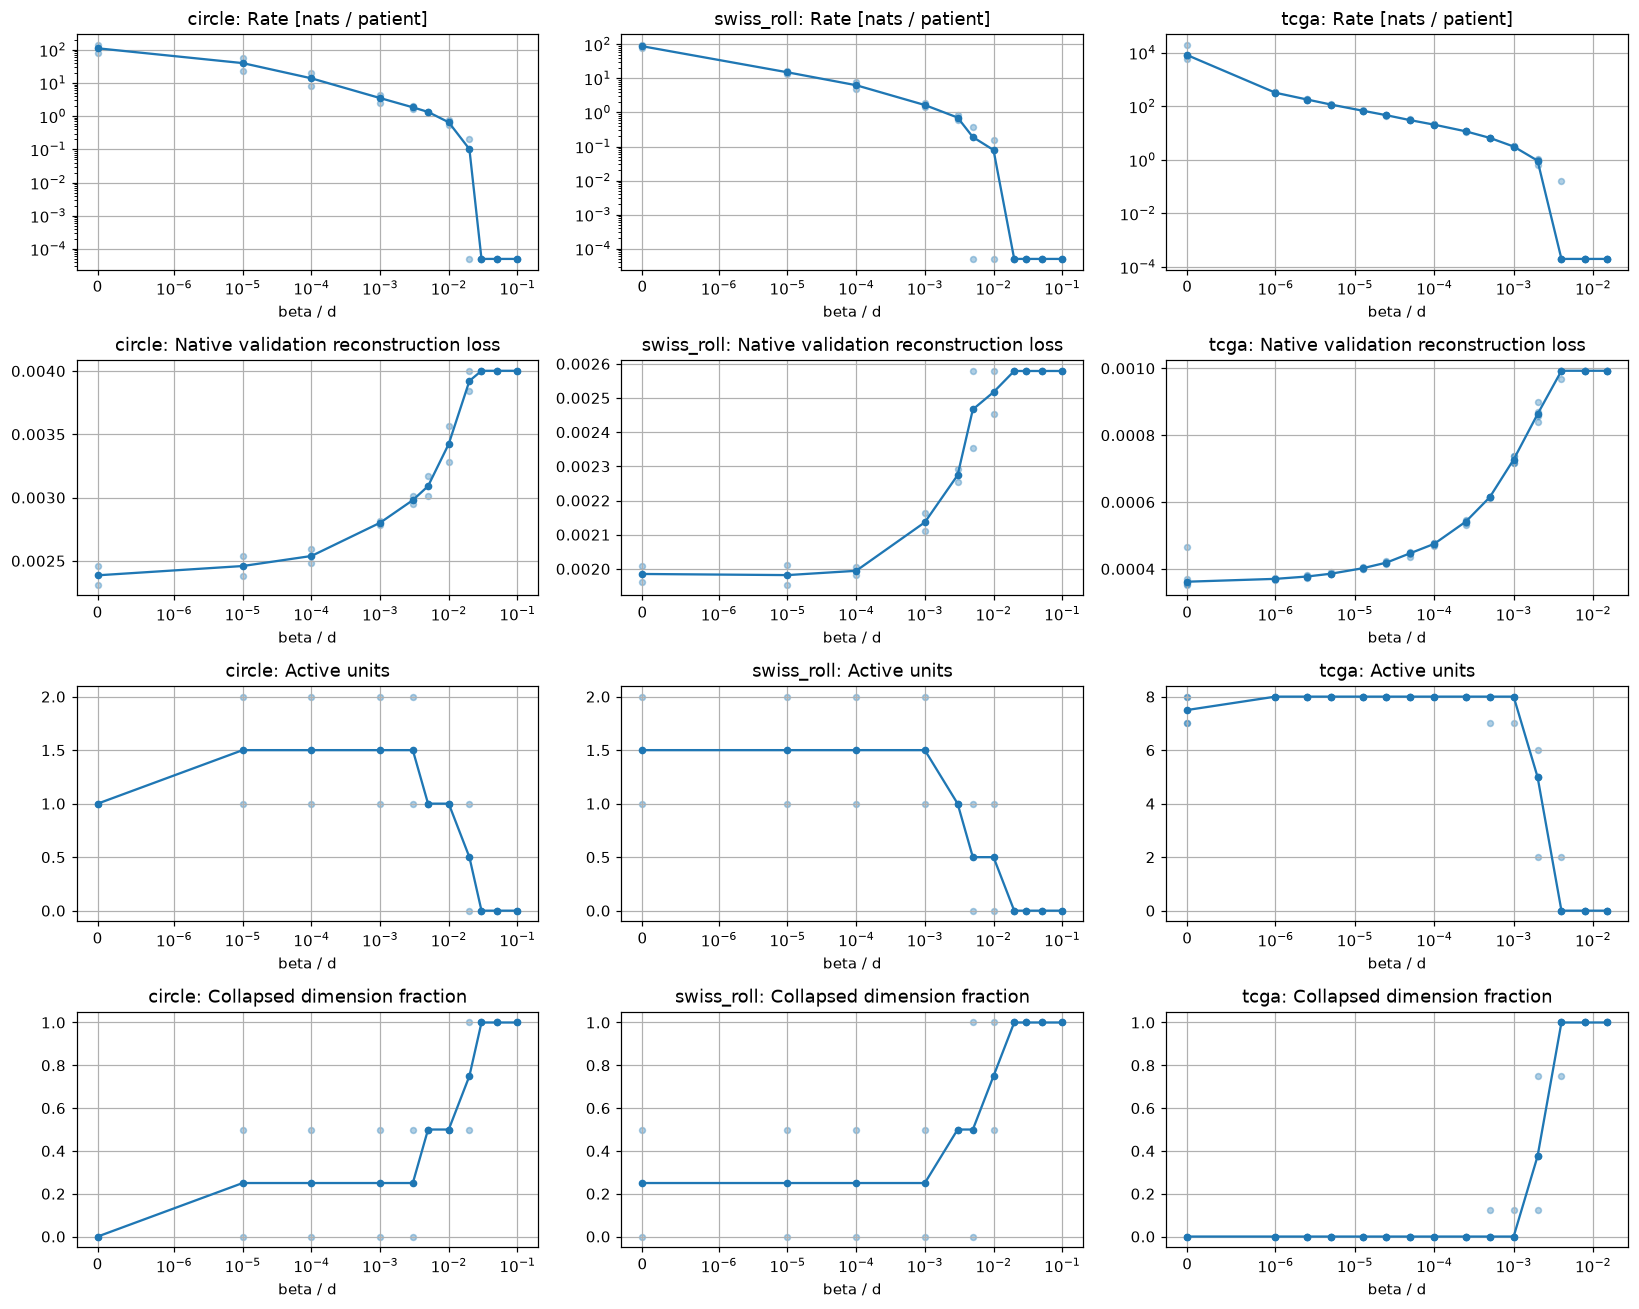

In [4]:
panels = [('rate','Rate [nats / patient]'), ('recon_valid_loss_native','Native validation reconstruction loss'),
          ('active_units','Active units'), ('collapsed_fraction','Collapsed dimension fraction')]
fig, axes = plt.subplots(len(panels), 3, figsize=(15, 12), squeeze=False)
for col, (dataset, group) in enumerate(main.groupby('dataset')):
    medians = group.groupby('beta_over_d').median(numeric_only=True)
    for row, (metric, title) in enumerate(panels):
        ax = axes[row, col]
        ax.scatter(group.beta_over_d, group[metric], alpha=.35, s=15)
        ax.plot(medians.index, medians[metric], 'o-', ms=4)
        ax.set_xscale('symlog', linthresh=1e-6)
        if metric == 'rate': ax.set_yscale('log')
        ax.set(title=f'{dataset}: {title}', xlabel='beta / d')
fig.tight_layout()
fig.savefig(OUTPUT / 'compression_courses.png', dpi=160)
plt.show()


## 3. Preservation gegen β und Rate

Höhere Trustworthiness, Continuity, LCMC, MRRE-Güte, Steadiness und Cohesiveness sind günstiger; niedriger skalennormierter Stress ist günstiger. Vorzeichen werden nicht automatisch umgedreht.

Der geometrische Referenzraum ist das tatsächlich vorverarbeitete X. Eine gute Erhaltung dieser Struktur ist nicht automatisch biologische Semantik oder gute AUC. Preservation auf μ enthält keine direkte Messung der Posterior-Überlappung.


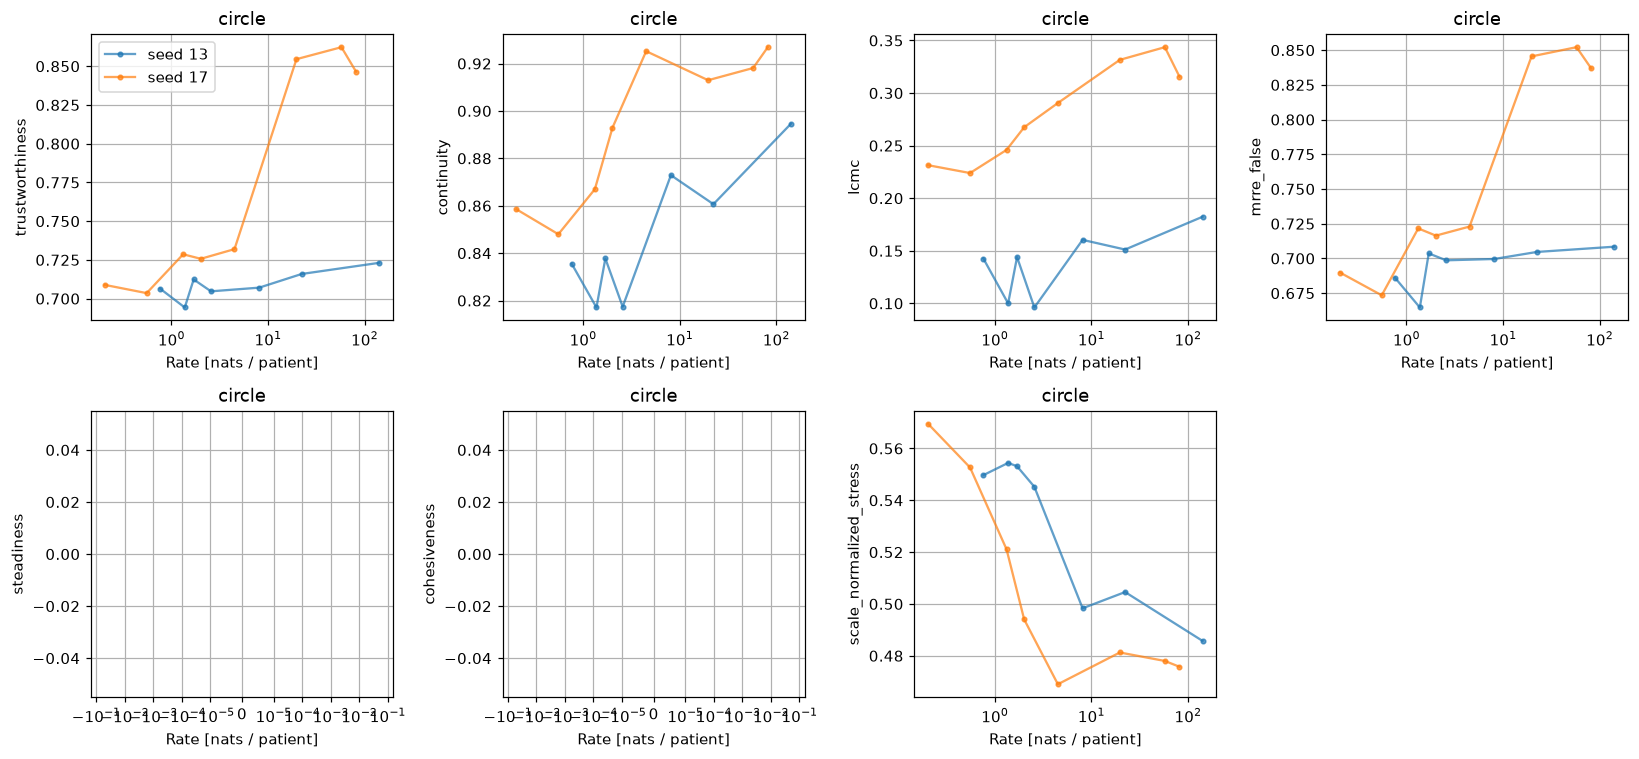

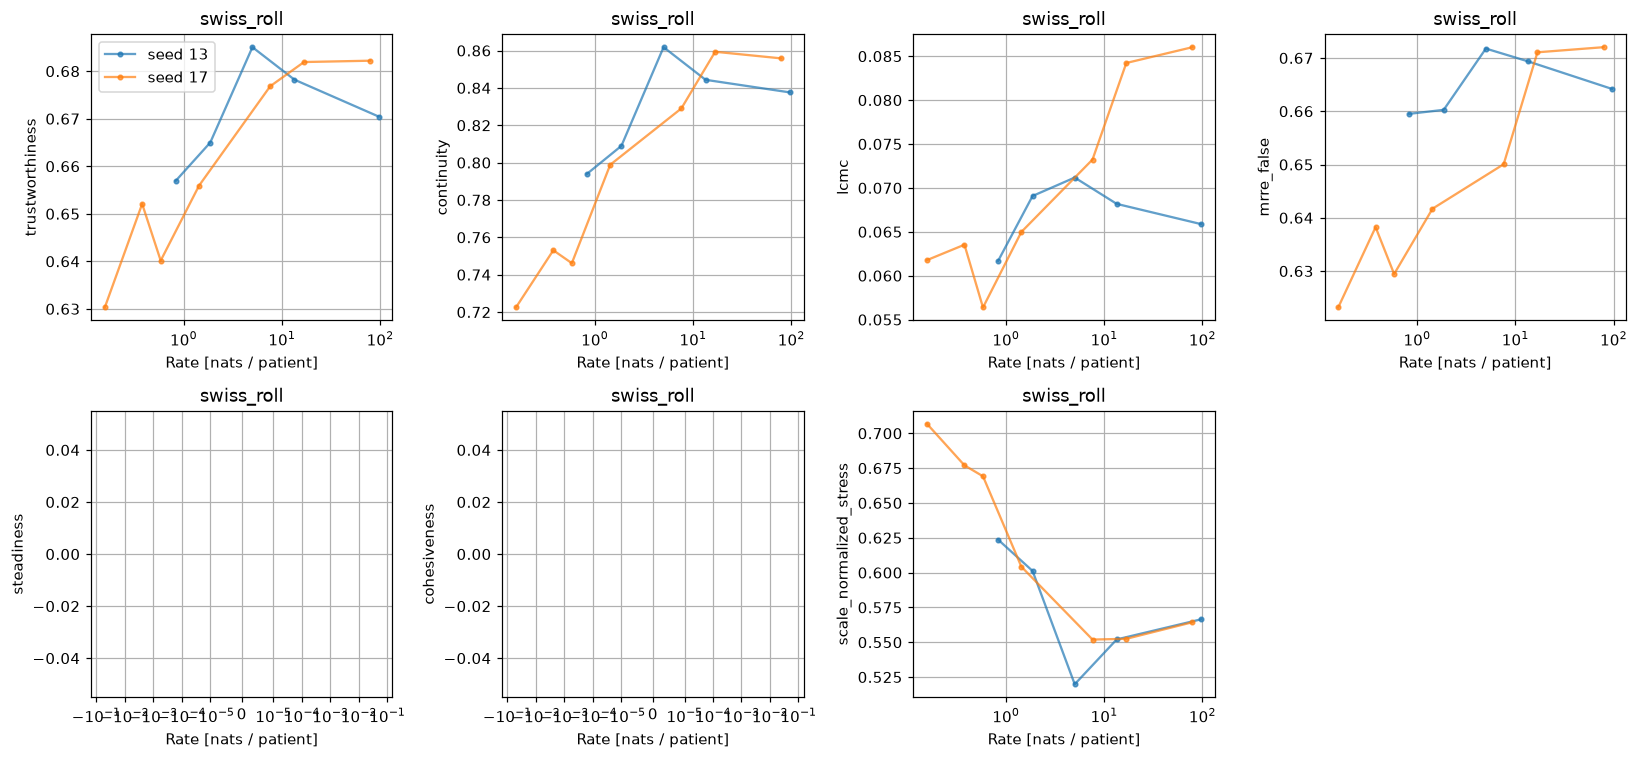

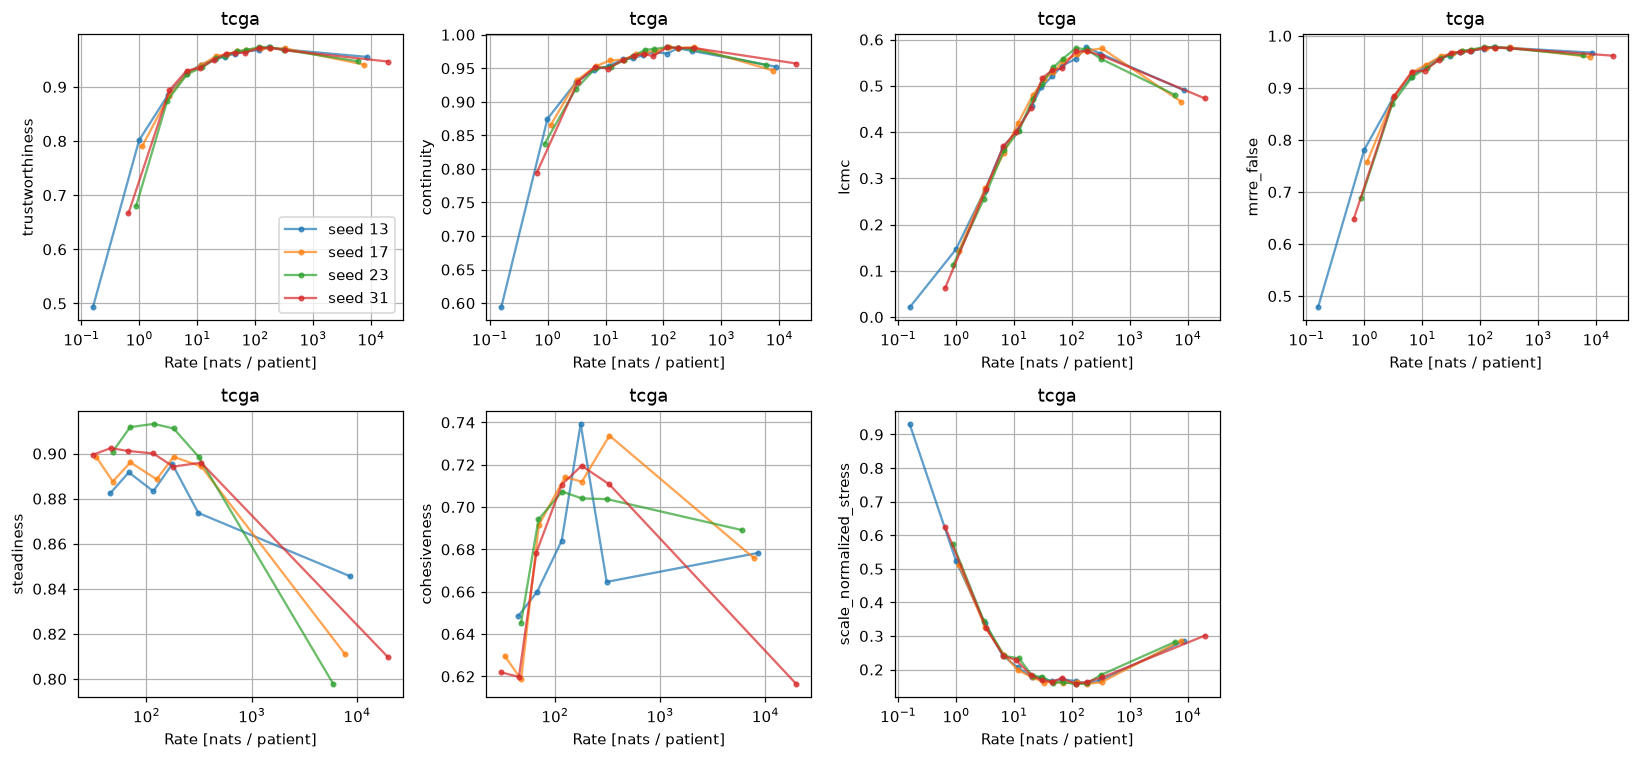

In [5]:
selected = ['trustworthiness','continuity','lcmc','mrre_false','steadiness','cohesiveness','scale_normalized_stress']
for dataset, group in main.groupby('dataset'):
    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    for ax, metric in zip(axes.flat, selected):
        for seed, trajectory in group.groupby('seed'):
            trajectory = trajectory.sort_values('rate')
            ax.plot(trajectory.rate, trajectory[metric], 'o-', ms=3, alpha=.7, label=f'seed {seed}')
        ax.set_xscale('symlog', linthresh=1e-5)
        ax.set(xlabel='Rate [nats / patient]', ylabel=metric, title=dataset)
    axes.flat[-1].axis('off')
    axes.flat[0].legend()
    fig.tight_layout()
    fig.savefig(OUTPUT / f'{dataset}_preservation_vs_rate.png', dpi=160)
    plt.show()


## 4. Pearson und Spearman: was folgt der Rate?

Drei Entscheidungen bleiben getrennt:
- **Rate vs. log-Rate:** Pearson hängt von dieser Transformation ab; Spearman sollte bei gleicher Punktmenge gleich bleiben.
- **Alle Zustände vs. vor vollständigem Collapse:** Unterschiede zeigen, wie stark Kollaps-Endpunkte die Korrelation treiben.
- **Werte vs. Steigungen:** Steigungen sind ΔMetrik/Δlog(β/d) und ΔRate/Δlog(β/d), nur β>0. Sie testen gemeinsame Änderungen statt bloß ähnlicher monotoner Verläufe.

Mindestens vier gültige Werte/Steigungen je Trajektorie. Keine Signifikanzsterne: β-Zustände sind keine unabhängigen Replikationen. TCGA hat vier, Geometrie nur zwei Trainingsseeds; Quartile sind deskriptiv, keine Konfidenzintervalle.


circle — preservation only, ranked by absolute Pearson


,metric,pearson,spearman,pearson_q25,pearson_q75,spearman_q25,spearman_q75,trajectories,min_pairs
69,scale_normalized_stress,-0.888944,-0.857143,-0.905796,-0.872092,-0.857143,-0.857143,2,7
70,spearman_rho,0.880899,0.940476,0.876535,0.885262,0.934524,0.946429,2,7
62,continuity,0.873364,0.845238,0.872477,0.874251,0.815476,0.875000,2,7
65,mrre_missing,0.871820,0.845238,0.868289,0.875351,0.815476,0.875000,2,7
71,trustworthiness,0.855566,0.815476,0.819561,0.891572,0.782738,0.848214,2,7
63,lcmc,0.816546,0.809524,0.754339,0.878753,0.761905,0.857143,2,7
64,mrre_false,0.783543,0.869048,0.706642,0.860444,0.863095,0.875000,2,7


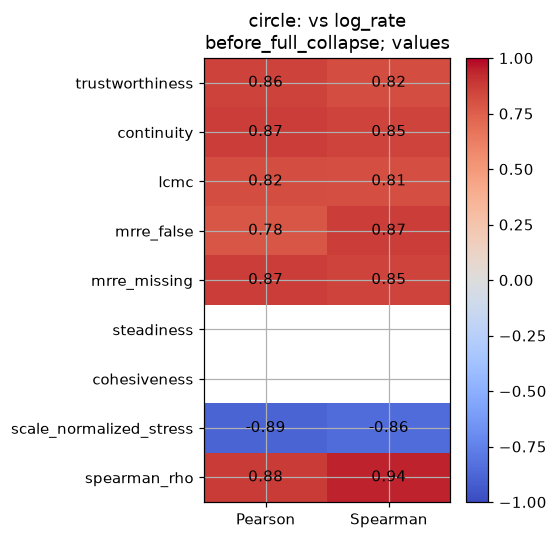

swiss_roll — preservation only, ranked by absolute Pearson


,metric,pearson,spearman,pearson_q25,pearson_q75,spearman_q25,spearman_q75,trajectories,min_pairs
166,spearman_rho,0.808593,0.746429,0.749556,0.867631,0.673214,0.819643,2,5
158,continuity,0.783136,0.764286,0.694406,0.871867,0.682143,0.846429,2,5
161,mrre_missing,0.766785,0.764286,0.668588,0.864983,0.682143,0.846429,2,5
165,scale_normalized_stress,-0.718971,-0.728571,-0.815877,-0.622065,-0.792857,-0.664286,2,5
167,trustworthiness,0.695325,0.782143,0.572396,0.818254,0.691071,0.873214,2,5
160,mrre_false,0.681167,0.782143,0.544762,0.817572,0.691071,0.873214,2,5
159,lcmc,0.558630,0.496429,0.374797,0.742464,0.298214,0.694643,2,5


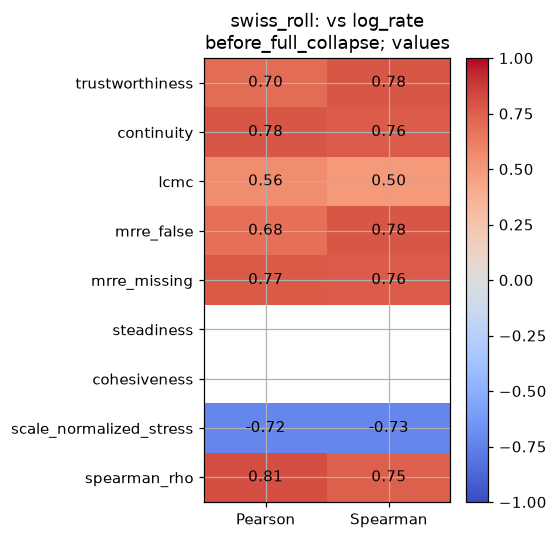

tcga — preservation only, ranked by absolute Pearson


,metric,pearson,spearman,pearson_q25,pearson_q75,spearman_q25,spearman_q75,trajectories,min_pairs
274,steadiness,-0.907822,-0.542857,-0.929836,-0.891750,-0.637500,-0.444643,4,6
266,lcmc,0.724069,0.828671,0.698482,0.767389,0.819930,0.843906,4,12
267,mrre_false,0.682038,0.828671,0.660510,0.708349,0.818182,0.852148,4,12
268,mrre_missing,0.649190,0.797203,0.618166,0.680330,0.767483,0.822428,4,12
275,trustworthiness,0.645853,0.783217,0.626382,0.674776,0.781469,0.807193,4,12
265,continuity,0.621730,0.755245,0.581966,0.655733,0.736014,0.764236,4,12
272,scale_normalized_stress,-0.499971,-0.562937,-0.571776,-0.461090,-0.604520,-0.545455,4,12
273,spearman_rho,0.450674,0.540959,0.359797,0.528444,0.484515,0.590909,4,12
263,cohesiveness,0.204449,0.371429,0.074649,0.275693,0.194643,0.550000,4,6


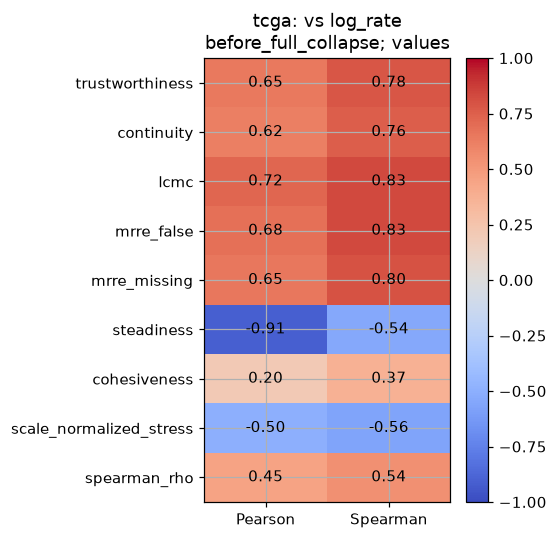

In [6]:
details, correlations = rate_correlations(runs)
details.to_csv(OUTPUT / 'rate_correlations_by_trajectory.csv', index=False)
correlations.to_csv(OUTPUT / 'rate_correlations_summary.csv', index=False)
RATE_REFERENCE = 'log_rate'
SCOPE = 'before_full_collapse'
MODE = 'values'
view = correlations[correlations.rate_reference.eq(RATE_REFERENCE)
    & correlations.scope.eq(SCOPE) & correlations['mode'].eq(MODE)
    & correlations.metric.isin(PRESERVATION)].copy()
for dataset, group in view.groupby('dataset'):
    print(dataset, '— preservation only, ranked by absolute Pearson')
    order = group.pearson.abs().sort_values(ascending=False).index
    display(group.loc[order, ['metric','pearson','spearman','pearson_q25','pearson_q75',
                              'spearman_q25','spearman_q75','trajectories','min_pairs']])
    plot = group.set_index('metric')[['pearson','spearman']].reindex(PRESERVATION)
    fig, ax = plt.subplots(figsize=(5, 5))
    image = ax.imshow(plot, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
    ax.set_xticks([0,1], ['Pearson','Spearman'])
    ax.set_yticks(range(len(plot)), plot.index)
    for i in range(len(plot)):
        for j in range(2):
            value = plot.iloc[i,j]
            if np.isfinite(value):ax.text(j,i,f'{value:.2f}',ha='center',va='center')
    ax.set_title(f'{dataset}: vs {RATE_REFERENCE}\n{SCOPE}; {MODE}')
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUT / f'{dataset}_rate_correlation_heatmap.png', dpi=160)
    plt.show()


## 5. Wie viel hängt an Collapse und monotonem Verlauf?

Die vollständige Tabelle enthält auch Active Units, Collapse und Rekonstruktion. **Rate pro Dimension ist bei festem d algebraisch proportional zur Rate**: ihre Korrelation ist eine Kontrolle und kein unabhängiger Befund.


In [7]:
for dataset in sorted(main.dataset.unique()):
    print(dataset)
    compare = correlations[correlations.dataset.eq(dataset)
        & correlations.rate_reference.eq('log_rate') & correlations.metric.isin(PRESERVATION)]
    display(compare.pivot(index='metric', columns=['scope','mode'], values='spearman').reindex(PRESERVATION))
    diagnostics = correlations[correlations.dataset.eq(dataset)
        & correlations.rate_reference.eq('log_rate') & correlations.scope.eq('all_models')
        & correlations['mode'].eq('values') & ~correlations.metric.isin(PRESERVATION)]
    display(diagnostics[['metric','pearson','spearman','trajectories','min_pairs']])
display(details.groupby(['dataset','scope','mode','status']).size().rename('correlations').to_frame())


circle


scope                   all_models           before_full_collapse          
mode                        slopes    values               slopes    values
metric                                                                     
trustworthiness          -0.414286  0.815476            -0.414286  0.815476
continuity               -0.192857  0.845238            -0.192857  0.845238
lcmc                     -0.107143  0.809524            -0.107143  0.809524
mrre_false               -0.328571  0.869048            -0.328571  0.869048
mrre_missing             -0.192857  0.845238            -0.192857  0.845238
steadiness                     NaN       NaN                  NaN       NaN
cohesiveness                   NaN       NaN                  NaN       NaN
scale_normalized_stress  -0.157143 -0.857143            -0.157143 -0.857143
spearman_rho              0.607143  0.940476             0.607143  0.940476

,metric,pearson,spearman,trajectories,min_pairs
12,active_units,0.903470,0.804907,2,11
13,collapsed_fraction,-0.929491,-0.904673,2,11
18,rate_per_dim,0.542578,1.000000,2,11
19,recon_generalization_gap,-0.905815,-0.946513,2,11
20,recon_valid_loss_native,-0.944556,-0.993007,2,11


swiss_roll


scope                   all_models           before_full_collapse          
mode                        slopes    values               slopes    values
metric                                                                     
trustworthiness                0.4  0.782143                  0.4  0.782143
continuity                     0.1  0.764286                  0.1  0.764286
lcmc                          -0.6  0.496429                 -0.6  0.496429
mrre_false                     0.3  0.782143                  0.3  0.782143
mrre_missing                   0.1  0.764286                  0.1  0.764286
steadiness                     NaN       NaN                  NaN       NaN
cohesiveness                   NaN       NaN                  NaN       NaN
scale_normalized_stress       -0.5 -0.728571                 -0.5 -0.728571
spearman_rho                   0.7  0.746429                  0.7  0.746429

,metric,pearson,spearman,trajectories,min_pairs
108,active_units,0.899903,0.894860,2,11
109,collapsed_fraction,-0.866068,-0.844561,2,11
114,rate_per_dim,0.554869,1.000000,2,11
115,recon_generalization_gap,-0.836211,-0.856499,2,11
116,recon_valid_loss_native,-0.961279,-0.980309,2,11


tcga


scope                   all_models           before_full_collapse          
mode                        slopes    values               slopes    values
metric                                                                     
trustworthiness           0.660606  0.783217             0.660606  0.783217
continuity                0.618182  0.755245             0.618182  0.755245
lcmc                      0.633333  0.828671             0.633333  0.828671
mrre_false                0.672727  0.828671             0.672727  0.828671
mrre_missing              0.715152  0.797203             0.715152  0.797203
steadiness               -0.100000 -0.542857            -0.100000 -0.542857
cohesiveness             -0.550000  0.371429            -0.550000  0.371429
scale_normalized_stress  -0.696970 -0.562937            -0.696970 -0.562937
spearman_rho              0.406061  0.540959             0.406061  0.540959

,metric,pearson,spearman,trajectories,min_pairs
206,active_units,0.917573,0.690707,4,15
208,collapsed_fraction,-0.928265,-0.778060,4,15
213,rate_per_dim,0.421184,1.000000,4,15
214,recon_generalization_gap,-0.897244,-0.967748,4,15
215,recon_valid_loss_native,-0.928056,-0.996422,4,15


correlations
dataset    scope                mode   status                                
circle     all_models           slopes insufficient_or_constant             8
                                       ok                                  48
                                values insufficient_or_constant             8
                                       ok                                  48
           before_full_collapse slopes insufficient_or_constant            12
                                       ok                                  44
                                values insufficient_or_constant            10
                                       ok                                  46
swiss_roll all_models           slopes insufficient_or_constant            22
                                       ok                                  34
                                values insufficient_or_constant             8
                                       ok                                  48
           before_full_collapse slopes insufficient_or_constant            32
                                       ok                                  24
                                values insufficient_or_constant             8
                                       ok                                  48
tcga       all_models           slopes ok                                 112
                                values ok                                 112
           before_full_collapse slopes ok                                 112
                                values ok                                 112

## 6. Weight-Decay-Kontrollen und Konvergenz

Nur TCGA, β=0, Seeds 13/17: Vergleich WD=0 mit WD=0,01. Zwei Seeds erlauben eine Diagnose, aber keine belastbare allgemeine Effektgröße.

Konvergenz: Mittel des nativen Validation-Rekonstruktionslosses in Epochen 451–500 gegen 701–750. Ein flacher nativer Rekonstruktionsloss allein beweist keine stabile AUC oder Rate. Dafür werden später Snapshot-Verläufe ergänzt.


In [8]:
reference = main[main.dataset.eq('tcga') & main.beta_over_d.eq(0) & main.seed.isin([13,17])]
control_table = pd.concat([reference, controls]).sort_values(['seed','weight_decay'])
display(control_table[['seed','weight_decay','rate','active_units','collapsed_fraction',
                       'recon_valid_loss_native','trustworthiness','steadiness']])
control_table.to_csv(OUTPUT / 'weight_decay_controls.csv', index=False)
manifest = json.loads((SERIES / 'launcher.json').read_text())
convergence_rows = []
for job in manifest['jobs']:
    folder = Path(job['output'])
    history = pd.read_csv(next(folder.glob('run_analysis/*/epoch_losses.csv')))
    valid = history[history.split.eq('valid')]
    middle = valid[valid.epoch.between(451,500)].recon_loss.mean()
    end = valid[valid.epoch.between(701,750)].recon_loss.mean()
    convergence_rows.append(dict(job_name=job['name'], recon_epochs451_500=middle,
                                recon_epochs701_750=end, relative_change=(end-middle)/middle))
convergence = runs[['job_name','dataset','beta_over_d','seed','weight_decay']].merge(
    pd.DataFrame(convergence_rows), on='job_name', validate='one_to_one')
convergence.to_csv(OUTPUT / 'reconstruction_convergence.csv', index=False)
display(convergence.groupby('dataset').relative_change.agg(['median','min','max']))
display(convergence.reindex(convergence.relative_change.abs().sort_values(ascending=False).index).head(12))


,seed,weight_decay,rate,active_units,collapsed_fraction,recon_valid_loss_native,trustworthiness,steadiness
44,13,0.00,19771.595708,8,0.0,0.000363,0.949941,0.802913
46,13,0.01,8608.840426,8,0.0,0.000353,0.955381,0.845561
45,17,0.00,49456.609796,7,0.0,0.000376,0.947511,0.843639
47,17,0.01,7730.681308,8,0.0,0.000354,0.940993,0.810894


,median,min,max
dataset,,,
circle,-0.000660,-0.012055,0.014207
swiss_roll,0.000110,-0.007281,0.016737
tcga,-0.003704,-0.012973,0.607745


,job_name,dataset,beta_over_d,seed,weight_decay,recon_epochs451_500,recon_epochs701_750,relative_change
48,tcga_b0_s23_wd0.01,tcga,0.000000,23,0.01,0.000396,0.000637,0.607745
49,tcga_b0_s31_wd0.01,tcga,0.000000,31,0.01,0.000394,0.000426,0.083289
45,tcga_b0_s17_wd0,tcga,0.000000,17,0.00,0.000548,0.000560,0.021418
22,swiss_roll_b0_s13_wd0.01,swiss_roll,0.000000,13,0.01,0.001931,0.001963,0.016737
2,circle_b1e-05_s13_wd0.01,circle,0.000010,13,0.01,0.002580,0.002617,0.014207
89,tcga_b0.001_s31_wd0.01,tcga,0.001000,31,0.01,0.000723,0.000714,-0.012973
11,circle_b0.005_s17_wd0.01,circle,0.005000,17,0.01,0.003176,0.003137,-0.012055
8,circle_b0.003_s13_wd0.01,circle,0.003000,13,0.01,0.003045,0.003012,-0.010850
69,tcga_b2.5e-05_s31_wd0.01,tcga,0.000025,31,0.01,0.000427,0.000423,-0.010591
78,tcga_b0.00025_s13_wd0.01,tcga,0.000250,13,0.01,0.000540,0.000535,-0.010448


## Weitere Bausteine

1. **Downstream-AUC/R²** auf z, passende klinische Kohorten und wiederholte Ziehungen.
2. **AUC vs. Preservation und Rate**, danach ANCOVA auf der neuen Serie; alte historische Auswahl separat validieren.
3. **Mehrskalige Preservation:** k=10/20/40, relative k-Werte, geprüfte R_NX-Kurven.
4. **Graph und TDA**, einschließlich Vergleich ihrer zusätzlichen Information.
5. **Epoch-Verläufe**, um Konvergenz und spätere Annealing-Reaktionszeiten zu beurteilen.

Dieser erste Block beantwortet **„Was folgt der Kompression?“**. Er beantwortet noch nicht **„Was erhält Downstream-Information?“**. Ein hoher Zusammenhang mit Rate ist dafür weder automatisch gut noch automatisch schlecht.
